# Neural Networks and Deep Learning — Lecture 9: Graph neural networks
Prof. dr. Daniel Traian Pele — Bucharest University of Economic Studies (ASE); Romanian Academy, Institute for Economic Forecasting (IPE)

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/notebooks/L9_notebook.ipynb)

This notebook reproduces the numbers and charts of the lecture from the real data in `../data/clean` (see `../data/SOURCES.md`). Section numbers (§) match the *Experiment yourself* pointers on the slides.

In [1]:
# Google Colab: copy the course repository, so that the data and the saved results are found
import os, subprocess, sys
if 'google.colab' in sys.modules and not os.getcwd().startswith('/content/NEURAL_BIZ'):
    if not os.path.isdir('/content/NEURAL_BIZ'):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/danpele/NEURAL_BIZ.git', '/content/NEURAL_BIZ'], check=True)
    os.chdir('/content/NEURAL_BIZ/notebooks')

In [2]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
DATA = '../data/clean/'
SEED = 20261108
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
except ImportError:
    DEVICE = 'cpu'
plt.rcParams.update({'figure.facecolor': 'none', 'axes.facecolor': 'none', 'axes.grid': False,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})
print('device:', DEVICE)

device: mps


## §1 The Elliptic graph
Nodes = Bitcoin transactions, edges = payment flows, 49 time steps; train on steps 1–34, test on 35–49 (Weber et al., 2019).

In [3]:
import subprocess, sys, urllib.request
try:
    import torch_geometric
except ImportError:                                   # Google Colab: install PyTorch Geometric
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'torch_geometric'], check=True)
import torch, torch.nn.functional as F
from torch_geometric.nn import GCNConv, SAGEConv, GATConv
from torch_geometric.utils import to_undirected
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, precision_score, recall_score, average_precision_score
RAW = '../data/raw/elliptic/'
os.makedirs(RAW, exist_ok=True)
for fn in ['elliptic_txs_features.csv.zip', 'elliptic_txs_edgelist.csv.zip', 'elliptic_txs_classes.csv.zip']:
    if not os.path.exists(RAW + fn):                  # about 146 MB, served by PyTorch Geometric
        urllib.request.urlretrieve('https://data.pyg.org/datasets/elliptic/' + fn, RAW + fn)
feat = pd.read_csv(RAW + 'elliptic_txs_features.csv.zip', header=None)
lab = pd.read_csv(RAW + 'elliptic_txs_classes.csv.zip')
edg = pd.read_csv(RAW + 'elliptic_txs_edgelist.csv.zip')
txid, step = feat[0].values, feat[1].values.astype(int)
X = feat.iloc[:, 2:].values.astype(np.float32)               # 93 local + 72 aggregated features
cls_map = dict(zip(lab.txId, lab['class'].astype(str)))
y = np.array([{'1': 1, '2': 0}.get(cls_map[t], -1) for t in txid])   # 1 illicit, 0 licit, -1 unknown
pos = {t: i for i, t in enumerate(txid)}
E = np.array([[pos[a] for a in edg.txId1], [pos[b] for b in edg.txId2]])
lab_m = y >= 0
train_m, test_m = lab_m & (step <= 34), lab_m & (step > 34)
fit_m, val_m = lab_m & (step < 30), lab_m & (step >= 30) & (step <= 34)
print('nodes', len(y), 'edges', E.shape[1], 'illicit', (y == 1).sum(), 'licit', (y == 0).sum(), 'unknown', (y == -1).sum())
print('labelled training', train_m.sum(), 'labelled test', test_m.sum(), 'illicit in test', (y[test_m] == 1).sum())

nodes 203769 edges 234355 illicit 4545 licit 42019 unknown 157205
labelled training 29894 labelled test 16670 illicit in test 1083


mean degree 2.3  median 2  max 473


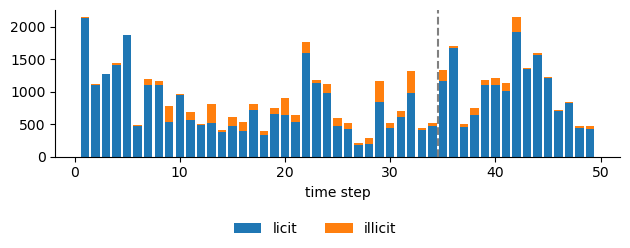

In [4]:
deg = np.bincount(E[0], minlength=len(y)) + np.bincount(E[1], minlength=len(y))
print('mean degree', round(deg.mean(), 2), ' median', int(np.median(deg)), ' max', deg.max())
c = pd.DataFrame({'step': step, 'y': y})
cnt = c[c.y >= 0].groupby(['step', 'y']).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(6.4, 2.5))
ax.bar(cnt.index, cnt[0], label='licit'); ax.bar(cnt.index, cnt[1], bottom=cnt[0], label='illicit')
ax.axvline(34.5, ls='--', color='grey'); ax.set_xlabel('time step'); fig.legend(loc='lower center', ncol=2)
fig.tight_layout(rect=(0, 0.12, 1, 1)); plt.show()

In [5]:
# label homophily: share of illicit among the labelled neighbours
src, dst = np.concatenate([E[0], E[1]]), np.concatenate([E[1], E[0]])
ill = np.bincount(src, weights=(y[dst] == 1), minlength=len(y)); labn = np.bincount(src, weights=(y[dst] >= 0), minlength=len(y))
for c_, name in [(1, 'illicit'), (0, 'licit')]:
    m = (y == c_) & (labn > 0)
    print(f'illicit share among neighbours of {name} nodes: {100 * np.mean(ill[m] / labn[m]):.1f} %')

illicit share among neighbours of illicit nodes: 51.0 %
illicit share among neighbours of licit nodes: 1.8 %


## §2 Baselines without the graph
Logistic regression and a random forest on the 165 features (72 of which are already aggregated over the neighbours).

In [6]:
mu, sd = X[step <= 34].mean(0), X[step <= 34].std(0) + 1e-6      # training steps only: no leakage
Xs = np.clip((X - mu) / sd, -10, 10).astype(np.float32)
ei = to_undirected(torch.tensor(E, dtype=torch.long))
xt, yt = torch.tensor(Xs), torch.tensor(np.where(y < 0, 0, y))
W = torch.tensor([0.3, 0.7])                                       # class weights of Weber et al. (2019)

def metrics(p, mask=test_m, thr=0.5):
    yy, pp = y[mask], p[mask]
    return dict(f1=round(f1_score(yy, pp >= thr), 3), prec=round(precision_score(yy, pp >= thr), 3),
                rec=round(recall_score(yy, pp >= thr), 3), prauc=round(average_precision_score(yy, pp), 3))

class GNN(torch.nn.Module):
    def __init__(self, kind, d_in, h=100, layers=2, heads=4, drop=0.2):
        super().__init__()
        self.kind, self.drop = kind, drop
        mk = {'gcn': lambda a: GCNConv(a, h), 'sage': lambda a: SAGEConv(a, h), 'gat': lambda a: GATConv(a, h // heads, heads=heads),
              'mlp': lambda a: torch.nn.Linear(a, h)}[kind]
        self.convs = torch.nn.ModuleList([mk(d_in if i == 0 else h) for i in range(layers)])
        self.out = torch.nn.Linear(h, 2)
    def embed(self, x, ei):
        for c in self.convs:
            x = F.dropout(F.relu(c(x) if self.kind == 'mlp' else c(x, ei)), self.drop, self.training)
        return x
    def forward(self, x, ei):
        return self.out(self.embed(x, ei))

def train(kind, layers=2, epochs=200, patience=30, seed=1):
    torch.manual_seed(seed)
    m = GNN(kind, xt.shape[1], layers=layers); opt = torch.optim.Adam(m.parameters(), lr=0.003, weight_decay=5e-4)
    best, state, wait = -1, None, 0
    fm = torch.tensor(fit_m)
    for ep in range(epochs):
        m.train(); opt.zero_grad()
        loss = F.cross_entropy(m(xt, ei)[fm], yt[fm], weight=W); loss.backward(); opt.step()
        m.eval()
        with torch.no_grad():
            p = torch.softmax(m(xt, ei), 1)[:, 1].numpy()
        ap = average_precision_score(y[val_m], p[val_m])
        if ap > best:
            best, wait, state = ap, 0, {k: v.clone() for k, v in m.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: break
    m.load_state_dict(state); m.eval()
    with torch.no_grad():
        return torch.softmax(m(xt, ei), 1)[:, 1].numpy(), m.embed(xt, ei).numpy()

In [7]:
lr = LogisticRegression(max_iter=3000, class_weight={0: 0.3, 1: 0.7}).fit(Xs[train_m], y[train_m])
p_lr = lr.predict_proba(Xs)[:, 1]
print('logistic, all features', metrics(p_lr))
rf = RandomForestClassifier(n_estimators=100, max_features=50, n_jobs=-1, random_state=1).fit(X[train_m], y[train_m])
p_rf = rf.predict_proba(X)[:, 1]
print('random forest         ', metrics(p_rf))

logistic, all features {'f1': 0.343, 'prec': 0.22, 'rec': 0.771, 'prauc': 0.311}


random forest          {'f1': 0.805, 'prec': 0.905, 'rec': 0.724, 'prauc': 0.781}


## §3 A graph convolutional network
$H^{(l+1)}=\mathrm{ReLU}(\hat A H^{(l)} W^{(l)})$, $\hat A=\tilde D^{-1/2}(A+I)\tilde D^{-1/2}$; full-batch training, loss on labelled steps 1–29, early stopping on steps 30–34. The MLP has the same layers without the edges.

In [8]:
p_gcn, emb = train('gcn')
print('GCN', metrics(p_gcn))
p_mlp, _ = train('mlp')
print('MLP', metrics(p_mlp))

GCN {'f1': 0.41, 'prec': 0.326, 'rec': 0.552, 'prauc': 0.348}


MLP {'f1': 0.516, 'prec': 0.55, 'rec': 0.486, 'prauc': 0.383}


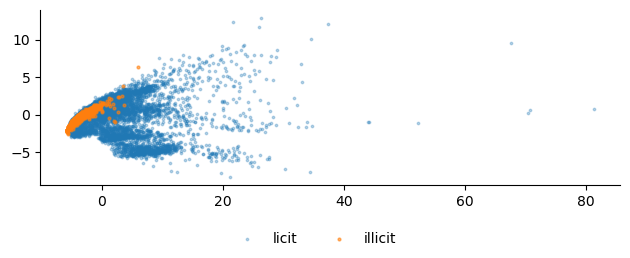

In [9]:
from sklearn.decomposition import PCA
Z = PCA(2).fit_transform(emb[test_m])
yy = y[test_m]
fig, ax = plt.subplots(figsize=(6.4, 2.6))
ax.scatter(Z[yy == 0, 0], Z[yy == 0, 1], s=3, alpha=0.3, label='licit')
ax.scatter(Z[yy == 1, 0], Z[yy == 1, 1], s=4, alpha=0.6, label='illicit')
fig.legend(loc='lower center', ncol=2); fig.tight_layout(rect=(0, 0.12, 1, 1)); plt.show()

## §4 GraphSAGE and GAT
GraphSAGE separates the node from the mean of its neighbours; GAT learns attention weights over the neighbours (4 heads).

In [10]:
p_sage, _ = train('sage')
print('GraphSAGE', metrics(p_sage))
p_gat, _ = train('gat', epochs=120)
print('GAT', metrics(p_gat))

GraphSAGE {'f1': 0.544, 'prec': 0.555, 'rec': 0.534, 'prauc': 0.547}


GAT {'f1': 0.489, 'prec': 0.527, 'rec': 0.457, 'prauc': 0.527}


## §5 Depth and over-smoothing
**Experiment yourself:** add 5 and 6 layers to the loop.

In [11]:
for L in [1, 2, 4]:
    p, e = train('gcn', layers=L, epochs=150)
    e = e[test_m] / (np.linalg.norm(e[test_m], axis=1, keepdims=True) + 1e-9)
    ii = np.random.default_rng(1).choice(len(e), (5000, 2))
    print(L, 'layers: PR-AUC', metrics(p)['prauc'], ' mean cosine similarity', round(float(np.mean(np.sum(e[ii[:, 0]] * e[ii[:, 1]], 1))), 2))

1 layers: PR-AUC 0.483  mean cosine similarity 0.59


2 layers: PR-AUC 0.348  mean cosine similarity 0.74


4 layers: PR-AUC 0.444  mean cosine similarity 0.95


## §6 Drift over time and the alert budget

In [12]:
rows = []
for s in range(35, 50):
    m = test_m & (step == s)
    rows.append({'step': s, 'rf': f1_score(y[m], p_rf[m] >= 0.5, zero_division=0), 'gcn': f1_score(y[m], p_gcn[m] >= 0.5, zero_division=0)})
f = pd.DataFrame(rows)
print(f.round(3).to_string(index=False))
for name, p in [('random forest', p_rf), ('GCN', p_gcn)]:
    o = np.argsort(-p[test_m])[:1000]
    print(f'{name}: top 1,000 alerts contain {100 * y[test_m][o].sum() / y[test_m].sum():.1f} % of the illicit, hit rate {100 * y[test_m][o].mean():.1f} %')

 step    rf   gcn
   35 0.969 0.635
   36 0.930 0.176
   37 0.758 0.387
   38 0.935 0.427
   39 0.944 0.357
   40 0.763 0.480
   41 0.952 0.470
   42 0.868 0.657
   43 0.000 0.020
   44 0.047 0.000
   45 0.000 0.000
   46 0.154 0.000
   47 0.000 0.000
   48 0.000 0.100
   49 0.033 0.000
random forest: top 1,000 alerts contain 72.9 % of the illicit, hit rate 79.0 %
GCN: top 1,000 alerts contain 35.5 % of the illicit, hit rate 38.5 %
